# Your Very First Machine Learning (ML) Model: Logistic Regression

Dataset: [College Student Placement Factors Dataset](https://www.kaggle.com/datasets/sahilislam007/college-student-placement-factors-dataset) (`data/college_student_placement_dataset.csv`)

**Mohamed Hiba · Week 07**

In [1]:
# Import our libraries.

from IPython.display import display

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, f1_score

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import statsmodels.api as sm

## Constants

It is a good programming practice to use constants to avoid repetition errors and to save yourself the effort of retyping the expression by _centralizing_ semantically identical values.

`DATASET_PATH` identifies the path to the dataset being loaded and operated on. `RANDOM_STATE` makes otherwise random operations reproducible run after run. Keep whatever value you set it to unless you want slightly different results.

In [2]:
from pathlib import Path
DATASET_PATH = next(str(p) for p in [Path('data/college_student_placement_dataset.csv'),
                                    Path('../data/college_student_placement_dataset.csv')] if p.exists())
RANDOM_STATE = 45  # Keep the assignment's required seed.

## Preliminary Inspection

See what the raw file looks like!

In [3]:
# Look at the first 5 lines of theraw contents of the file first.

with open(DATASET_PATH, "r") as file:
    for line_number in range(5):
        if line := file.readline():
            print(line)
        else:
            break  # Stop; there are less than 5 lines.

College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement

CLG0030,107,6.61,6.28,8,No,8,8,4,No

CLG0061,97,5.52,5.37,8,No,7,8,0,No

CLG0036,109,5.36,5.83,9,No,3,1,1,No

CLG0055,122,5.47,5.75,6,Yes,1,6,1,No



## Preliminary Load

Load the data. This is not the final form of the data which will be used, but it’s a `DataFrame` for further inspection so we can decide what to do with it next.

In [4]:
df = pd.read_csv(DATASET_PATH)
df

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No
...,...,...,...,...,...,...,...,...,...,...
9995,CLG0021,119,8.41,8.29,4,No,1,8,0,Yes
9996,CLG0098,70,9.25,9.34,7,No,0,7,2,No
9997,CLG0066,89,6.08,6.25,3,Yes,3,9,5,No
9998,CLG0045,107,8.77,8.92,3,No,7,5,1,No


## Null Values Check
Inspect which varibles may be good / not good for using as features based on null values. 


In [5]:
print(df.isna().sum())
print("Total missing values:", df.isna().sum().sum())

College_ID                0
IQ                        0
Prev_Sem_Result           0
CGPA                      0
Academic_Performance      0
Internship_Experience     0
Extra_Curricular_Score    0
Communication_Skills      0
Projects_Completed        0
Placement                 0
dtype: int64
Total missing values: 0


## Duplicate Rows Check
If so, remove the duplicates.

In [6]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()

Duplicate rows: 0


Many clean… 😐

## Categorical Categories

What are the categories for the categorial-looking (i.e., non-numeric) columns?

In [7]:
for column in df.select_dtypes(include=['object', 'str']).columns:
    if column != 'College_ID':
        print(column, df[column].unique())
print('College_ID is an identifier and will be excluded from predictors.')

Internship_Experience <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Placement <StringArray>
['No', 'Yes']
Length: 2, dtype: str
College_ID is an identifier and will be excluded from predictors.


## Feature Engineering

Non-numeric columns containing `'Yes'` and `'No'` do not work with logistic regression. Binary categories can be converted an integral type (`int`) with a value of 0 or 1.

In [8]:
for column in ['Internship_Experience', 'Placement']:
    df[column] = df[column].map({'Yes': 1, 'No': 0})
assert df[['Internship_Experience','Placement']].notna().all().all()
df.head()

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,0,8,8,4,0
1,CLG0061,97,5.52,5.37,8,0,7,8,0,0
2,CLG0036,109,5.36,5.83,9,0,3,1,1,0
3,CLG0055,122,5.47,5.75,6,1,1,6,1,0
4,CLG0004,96,7.91,7.69,7,0,8,10,2,0


Binary mapping is useful when a variable has exactly two categories with a clear interpretation, such as Yes = 1 and No = 0. For an unordered variable with several categories, one-hot encoding with `pd.get_dummies` avoids assigning a false numeric order. For a linear model with an intercept, one category can serve as the reference level.

# Visualization with `sns.pairplot`

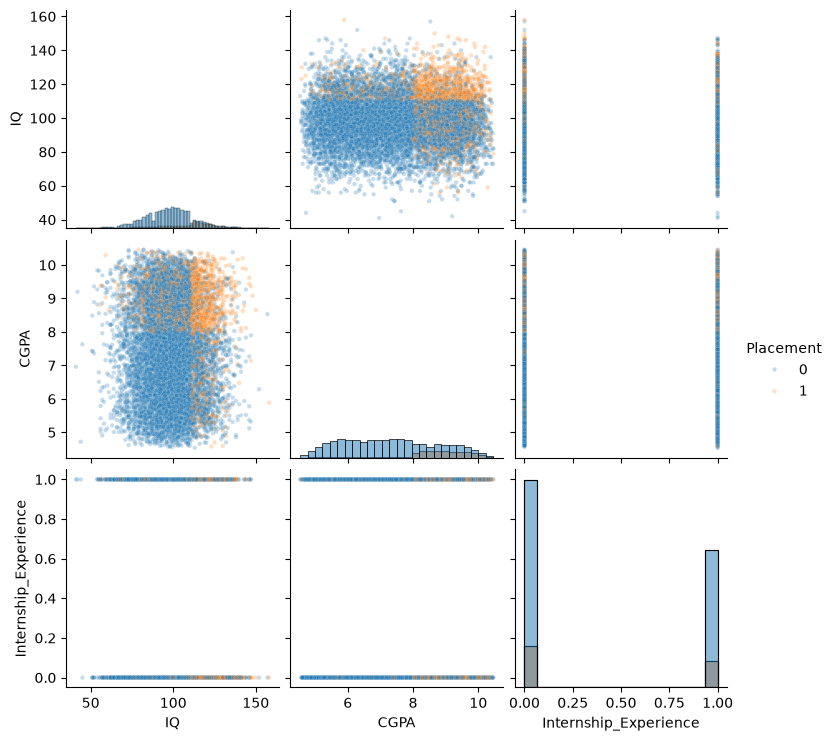

In [9]:
sns.pairplot(df[['IQ', 'CGPA', 'Internship_Experience', 'Placement']],
             hue='Placement', diag_kind='hist', plot_kws={'alpha': 0.25, 's': 10})
plt.show()

## Feature Selection 

Choose the columns corresponding to the features _IQ_ and _internship experience_ to be your `X`. Target _placement_ as your `y`.

In [10]:
X = df[['IQ', 'Internship_Experience']]
y = df['Placement']

## Split to Testing and Training Datasets 

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train: %d rows, %d columns" % X_train.shape)
print("X_test: %d rows, %d columns" % X_test.shape)
print("y_train: %d rows, 1 column" % y_train.shape)
print("y_test: %d rows, 1 column" % y_test.shape)

X_train: 8000 rows, 2 columns
X_test: 2000 rows, 2 columns
y_train: 8000 rows, 1 column
y_test: 2000 rows, 1 column


## Build and train your model

Initialize an empty Logistic Regression model, and then fit your model to your training data. 

In [12]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",45
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## Evaluation

Make predictions with your test data and save the predictions as `y_pred`.

In [13]:
y_pred = model.predict(X_test)
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(2000,))

Calculate and print the accuracy, precision, recall, and F1 scores of your model.

In [14]:
def scores(actual, predicted):
    return {'Accuracy': accuracy_score(actual, predicted),
            'Precision': precision_score(actual, predicted, zero_division=0),
            'Recall': recall_score(actual, predicted, zero_division=0),
            'F1': f1_score(actual, predicted, zero_division=0)}
for metric, value in scores(y_test, y_pred).items():
    print(f'{metric} Score: {value:.6f}')
print('Majority-class baseline accuracy:', y_train.value_counts(normalize=True).max())

Accuracy Score: 0.829000
Precision Score: 0.333333
Recall Score: 0.030120
F1 Score: 0.055249
Majority-class baseline accuracy: 0.834125


Plot a confusion matrix of your predicted results.

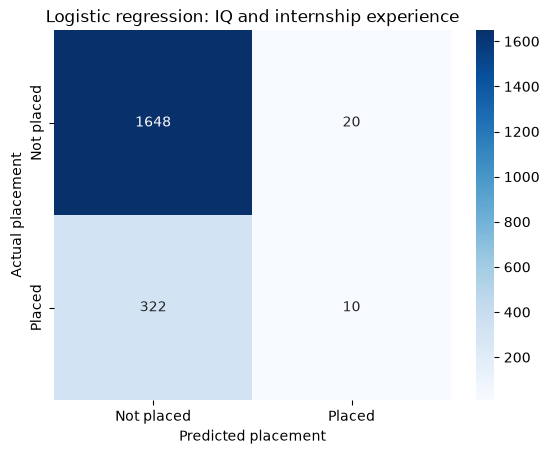

In [15]:
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not placed', 'Placed'], yticklabels=['Not placed','Placed'])
plt.xlabel('Predicted placement'); plt.ylabel('Actual placement')
plt.title('Logistic regression: IQ and internship experience')
plt.show()

How many true positives and true negatives did your model get?

In [16]:
true_negatives, false_positives, false_negatives, true_positives = cm.ravel()
print('True Negatives: %d' % true_negatives)
print('True Positives: %d' % true_positives)

True Negatives: 1648
True Positives: 10


Accuracy alone can hide poor recall when most students are not placed. The confusion matrix shows which class the baseline model misses.

# What is the Most Important Feature
 
Use `statsmodel` to create a summary report. Interpret the results.

In [17]:
X_train_const = sm.add_constant(X_train.astype(float))
logit_model = sm.Logit(y_train, X_train_const).fit(disp=False)
print(logit_model.summary())
print('\nOdds ratios per unit:')
print(np.exp(logit_model.params))

                           Logit Regression Results                           
Dep. Variable:              Placement   No. Observations:                 8000
Model:                          Logit   Df Residuals:                     7997
Method:                           MLE   Df Model:                            2
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                 0.09402
Time:                        17:33:36   Log-Likelihood:                -3256.4
converged:                       True   LL-Null:                       -3594.3
Covariance Type:            nonrobust   LLR p-value:                1.750e-147
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -7.3832      0.250    -29.481      0.000      -7.874      -6.892
IQ                        0.0559      0.002     24.125      0.000       0.051       0.060
Internsh

IQ has strong evidence of an association with placement in this two-feature model (coefficient ≈ 0.0559, p < 0.001). Each additional IQ point multiplies the predicted odds by about 1.0575, holding internship experience fixed. Ten additional points multiply the odds by about 1.75. Internship experience has coefficient ≈ −0.0174 and p ≈ 0.787, so this fit provides little evidence of a separate association after accounting for IQ. Of these two features, IQ contributes the clearer statistical signal. This conclusion does not imply a causal effect or establish that IQ is the most useful predictor among all available features.

# Extra Credit: Use your brain and make a better model (as in better scores).



,IQ + internship,All measured predictors
Accuracy,0.829000,0.904000
Precision,0.333333,0.773438
Recall,0.030120,0.596386
F1,0.055249,0.673469


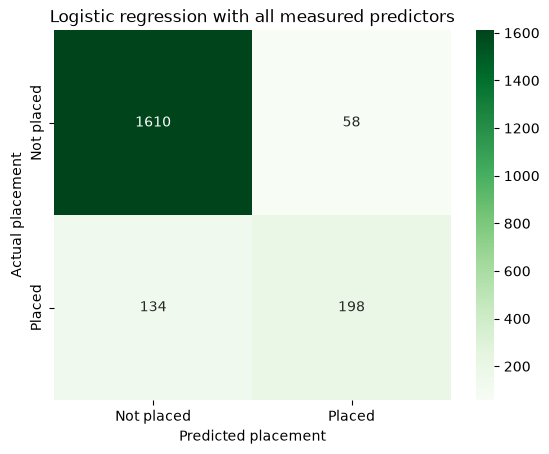

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Select all measured predictors in advance, excluding the identifier and target.
X_better = df.drop(columns=['College_ID', 'Placement'])
X_train_better = X_better.loc[X_train.index]
X_test_better = X_better.loc[X_test.index]
better_model = make_pipeline(StandardScaler(),
                             LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
better_model.fit(X_train_better, y_train)
y_pred_better = better_model.predict(X_test_better)
comparison = pd.DataFrame({'IQ + internship': scores(y_test,y_pred),
                           'All measured predictors': scores(y_test,y_pred_better)})
display(comparison)
cm_better = confusion_matrix(y_test,y_pred_better,labels=[0,1])
sns.heatmap(cm_better, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Not placed','Placed'], yticklabels=['Not placed','Placed'])
plt.xlabel('Predicted placement'); plt.ylabel('Actual placement')
plt.title('Logistic regression with all measured predictors')
plt.show()

The expanded model uses the exact same training and test rows as the baseline. Scaling learns only from the training rows through the pipeline. These additional predictors may improve discrimination, but one held-out split is an estimate rather than a guarantee. Further feature choices or threshold tuning should use cross-validation within the training set before evaluation on a fresh test set.